# Práctica de NunPy

Análisis de Distribuciones Probabilísticas con NumPy y Matplotlib

## Objetivos
- Aplicar los conceptos de generación de distribuciones aleatorias con **NumPy**.
- Calcular los **estadísticos descriptivos** de cada distribución.
- Representar visualmente los resultados utilizando **Matplotlib**.

---

## Indicaciones

1. **Generación de datos**
   - Genera **dos distribuciones aleatorias** de un tamaño de 1.000 observaciones cada una:
     - Una **Distribución Normal (Gaussiana)** con media y desvío estándar a elección.
     - Una **Distribución Uniforme** dentro de un rango que definas.

2. **Análisis estadístico**
   - Calcula para cada distribución los siguientes valores:
     - Media (`mean`)
     - Mediana (`median`)
     - Varianza (`var`)
     - Desvío estándar (`std`)
     - Mínimo y máximo (`min`, `max`)

3. **Visualización**
   - Utiliza **Matplotlib** para crear **dos subplots (gráficos)** en una misma figura:
     - En el **subplot izquierdo**, muestra el **histograma de la distribución normal**.
     - En el **subplot derecho**, muestra el **histograma de la distribución uniforme**.
   - Agrega título general, etiquetas de ejes, leyenda y grilla en cada gráfico.     - Agrega título, leyenda y etiquetas de ejes.

4. **Reflexión**
   - Describe brevemente (en una celda Markdown) las diferencias observadas entre ambas distribuciones según los resultados y el gráfico.

---

## Criterios de evaluación
- Correcta implementación de PEP8
- Correcto uso de celdas markdown y de código en el Jupyter Notebook.
- Correcta implementación de las funciones de NumPy.
- Cálculo adecuado de los estadísticos descriptivos.
- Uso apropiado y estético de Matplotlib para la visualización.
- Claridad en la interpretación final.




In [1]:
import matplotlib.pyplot as plt
import numpy as np
from PIL.ImageOps import scale


## Datos
Se generan 1000 observaciones de una distribución normal (media 50, desvío 10) y de una unifrome en el rango [20, 80). Se fija una para que los resultados sean reproducibles.

In [27]:
N_OBSERVACIONES = 1000
MEDIA_NORMAL = 50
DESVIO_NORMAL = 10
LIMITE_INFERIOR = 20
LIMITE_SUPERIOR = 80

np.random.seed(42)

dist_normal = np.random.normal(loc=MEDIA_NORMAL, scale = DESVIO_NORMAL, size=N_OBSERVACIONES)
dist_uniforme = np.random.uniform(low=LIMITE_INFERIOR, high=LIMITE_SUPERIOR, size=N_OBSERVACIONES)

dist_normal[:5].round(2), dist_uniforme[:5].round(2)

(array([54.97, 48.62, 56.48, 65.23, 47.66]),
 array([30.05, 26.27, 58.19, 62.39, 21.9 ]))

## Análisis estadístico
Se calculan los estadísticos descriptivos de cada distribución.
En cada resultado, el primer valor corresponde a la **normal** y el segundo a la **uniforme**.

##### Media

In [28]:
np.mean(dist_normal).round(2)

np.float64(50.19)

In [29]:
np.mean(dist_uniforme).round(2)

np.float64(50.22)

##### Mediana

In [30]:
np.median(dist_normal).round(2)

np.float64(50.25)

In [31]:
np.median(dist_uniforme).round(2)

np.float64(50.97)

##### Varianza

In [32]:
np.var(dist_normal).round(2)

np.float64(95.79)

In [33]:
np.var(dist_uniforme).round(2)

np.float64(299.04)

##### Desvío estándar

In [34]:
np.std(dist_normal).round(2)

np.float64(9.79)

In [35]:
np.std(dist_uniforme).round(2)

np.float64(17.29)

##### Mínimo y máximo

In [36]:
np.min(dist_normal).round(2)

np.float64(17.59)

In [37]:
np.max(dist_normal).round(2)

np.float64(88.53)

In [38]:
np.min(dist_uniforme).round(2)

np.float64(20.19)

In [39]:
np.max(dist_uniforme).round(2)

np.float64(79.96)

## Visualización
Histograma de ambas distribuciones, con líneas de mediana y media

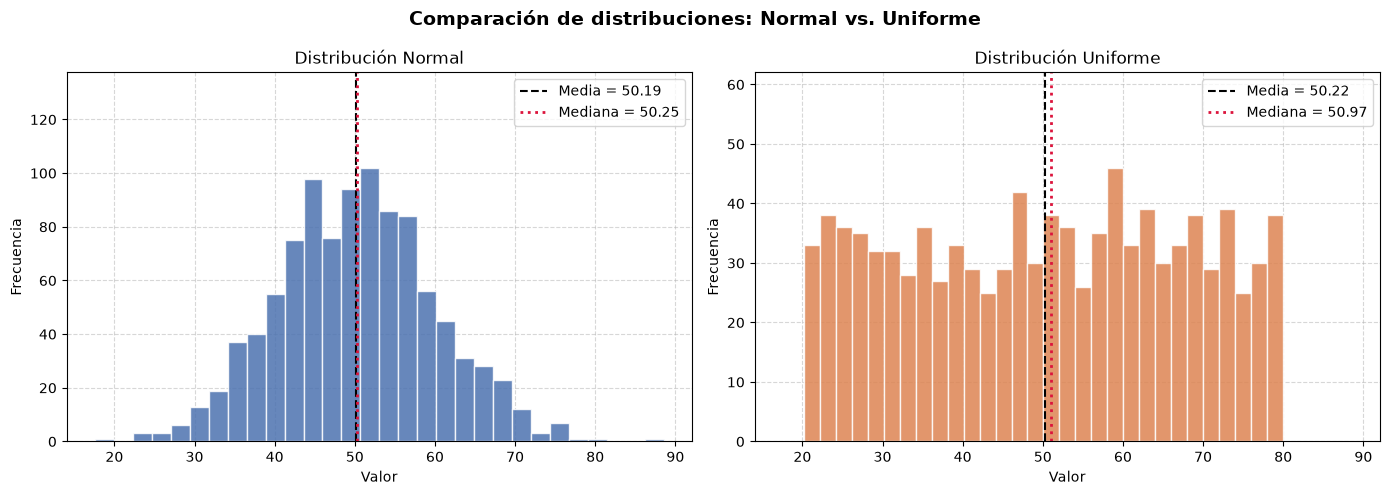

In [42]:
fig, (ax_normal, ax_uniforme) = plt.subplots(1, 2, figsize=(14, 5),
                                             sharex=True)

configuracion = [
    (ax_normal, dist_normal, 'Distribución Normal', '#4C72B0'),
    (ax_uniforme, dist_uniforme, 'Distribución Uniforme', '#DD8452'),
]

for ax, datos, titulo, color in configuracion:
    media = np.mean(datos)
    mediana = np.median(datos)
    frecuencias, _, _ = ax.hist(datos, bins=30, color=color,
                                edgecolor='white', alpha=0.85,)
    ax.axvline(media, color='black', linestyle='--', linewidth=1.5,
               label=f'Media = {media:.2f}')
    ax.axvline(mediana, color='crimson', linestyle=':', linewidth=2,
               label=f'Mediana = {mediana:.2f}')
    ax.set_ylim(0, frecuencias.max() * 1.35)
    ax.set_title(titulo, fontsize=12)
    ax.set_xlabel('Valor')
    ax.set_ylabel('Frecuencia')
    ax.legend(loc='upper right')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_axisbelow(True)

fig.suptitle('Comparación de distribuciones: Normal vs. Uniforme',
             fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()

## Refelxión

Ambas distribuciones tienen una media cercana a 50 y media ≈ mediana, por lo
que las dos son **simétricas**. La diferencia está en la forma y la dispersión.

- **Forma:** la normal tiene forma de **campana**, con los valores concentrados
  cerca de la media. La uniforme es **plana**, ya que, todos los valores del rango
  aparecen con frecuencia parecida.
- **Dispersión:** la uniforme está mucho más dispersa (varianza ≈ 299,
  desvío ≈ 17,3) que la normal (varianza ≈ 96, desvío ≈ 9,8).
- **Extremos:** la uniforme nunca sale del rango [20, 80). La normal no tiene
  límites, por eso aparecen valores como 17,6 o 88,5, aunque son muy poco
  frecuentes.

Por lo que tener la misma media no implica tener la misma distribución.